# Álgebra Linear e Otimização Contínua para Machine Learning
## Notebook Exploratório e Validação Numérica em NumPy Puro

Este notebook consolida implementações do zero em **NumPy puro** para os principais fundamentos matemáticos que governam estimadores clássicos e algoritmos de treinamento em Aprendizado de Máquina: geometria métrica, decomposições espectrais e SVD, cálculo matricial em superfícies de perda, condicionamento, otimização estocástica/adaptativa e métodos proximais esparsos.

---

### Diretrizes de Implementação

1. **NumPy Puro Exclusivo:** Todas as rotinas, métricas, decomposições matriciais, sistemas lineares e otimizadores são implementados **exclusivamente com `numpy`** (e `matplotlib` para visualizações), sem recorrer a solvers prontos (`scikit-learn`, `scipy.optimize`, `pytorch`, etc.).
2. **Rigor Teórico-Computacional:** Cada experimento numérico valida identidades algébricas e taxas teóricas deduzidas analiticamente.
3. **Tolerância Numérica:** Asserções explícitas checam equivalência entre teoria e código na faixa de $10^{-10}$ a $10^{-15}$.

In [1]:
import sys
from pathlib import Path

if str(Path('.').resolve()) not in sys.path:
    sys.path.insert(0, str(Path('.').resolve()))

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

np.random.seed(42)
np.set_printoptions(precision=6, suppress=True)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Ambiente configurado com sucesso! NumPy versão:', np.__version__)

mkdir -p failed for path /home/vscode/.cache/matplotlib: [Errno 13] Permission denied: '/home/vscode/.cache/matplotlib'


Matplotlib created a temporary cache directory at /tmp/matplotlib-f5lif1ef because there was an issue with the default path (/home/vscode/.cache/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Ambiente configurado com sucesso! NumPy versão: 2.5.4


---
## Conjuntos de Dados de Referência

Definição canônica dos sistemas de dados utilizados nos experimentos:

1. **Dataset $\mathcal{D}$ (Avaliação Imobiliária):** $N=6$ amostras com $d=2$ atributos (Área $x_1$ e Idade $x_2$), alvo contínuo de preço $y$ e rótulo binário $c \in \{0, 1\}$. Ponto de consulta: $\mathbf{x}_{\text{novo}} = [6{,}0, 20{,}0]^T$.
2. **Matriz $\mathcal{A}$:** Sistema $3 \times 2$ de posto completo para projeções ortogonais, decomposição polar e SVD compacta.
3. **Matriz $\mathcal{B}$:** Sistema $3 \times 3$ com colinearidade exata ($\mathbf{b}_3 = \mathbf{b}_1 + \mathbf{b}_2$) para estudo de curvatura nula e regularização Ridge.
4. **Dados Sintéticos Esparsos:** Sistema $50 \times 10$ com suporte verdadeiro de tamanho 3 para validação de recuperação esparsa via ISTA e FISTA.

In [2]:
from src.datasets import get_dataset_d
X_data, y_prices, c_labels, x_novo = get_dataset_d()
print('Shape X_data:', X_data.shape)
print('Shape y_prices:', y_prices.shape)
print('Shape c_labels:', c_labels.shape)

Shape X_data: (6, 2)
Shape y_prices: (6,)
Shape c_labels: (6,)


In [3]:
from src.datasets import get_system_a, get_system_b, get_sparse_synthetic_data
A_mat, y_A = get_system_a()
B_mat, y_B, beta_0 = get_system_b()
X_syn, y_syn, w_true = get_sparse_synthetic_data()
print('Shape A_mat:', A_mat.shape, '| Shape B_mat:', B_mat.shape, '| Shape X_syn:', X_syn.shape)

Shape A_mat: (3, 2) | Shape B_mat: (3, 3) | Shape X_syn: (50, 10)


---
## Questão 1: Normas, Métricas, Escala e o Algoritmo $k$-NN

**Objetivo:** Implementar em NumPy puro as funções de cálculo de distância ($L_1, L_2, L_\infty$ e Mahalanobis com matriz de covariância amostral $\mathbf{S}$), padronização de atributos (Z-score e MinMax), e o classificador/regressor $k$-NN ($k=3$).

> **Item a preencher:** Calcule as distâncias de cada amostra ao ponto $\mathbf{x}_{\text{novo}} = [6{,}0, 20{,}0]^T$ com e sem padronização, e discuta a distorção induzida pela escala da variável 'Idade' ($x_2$).

=== QUESTÃO 1: NORMAS, MÉTRICAS, ESCALA E k-NN ===
Amostra |   d_L1 (Rank) |   d_L2 (Rank) | d_Linf (Rank) | d_L2_Z (Rank) | d_Mahal (Rank)
   1    |  11.00 (3º)   | 10.0499 (3º)  |  10.00 (3º)   | 1.0358 (3º)  | 1.0773 (3º)
   2    |  19.00 (4º)   | 18.0278 (5º)  |  18.00 (5º)   | 1.7811 (4º)  | 1.7525 (4º)
   3    |  23.00 (6º)   | 20.2237 (6º)  |  20.00 (6º)   | 2.2292 (6º)  | 2.1377 (5º)
   4    |   3.50 (1º)   | 2.6926 (1º)  |   2.50 (1º)   | 0.9257 (2º)  | 0.9206 (1º)
   5    |   7.00 (2º)   | 5.3852 (2º)  |   5.00 (2º)   | 0.8813 (1º)  | 0.9280 (2º)
   6    |  19.00 (5º)   | 15.5242 (4º)  |  15.00 (4º)   | 2.0684 (5º)  | 2.1865 (6º)
Contraexemplo Cosseno: d_cos(u,w)=1.0000 > d_cos(u,v)+d_cos(v,w)=0.5858
k-NN Bruto (L2): k=1 -> classe 0 (vizinho [4]); k=3 -> classe 0, y_hat=2.966667 (vizinhos [4 5 1])
k-NN Z-Score (L2): k=1 -> classe 1 (vizinho [5]); k=3 -> classe 0, y_hat=2.966667 (vizinhos [5 4 1])



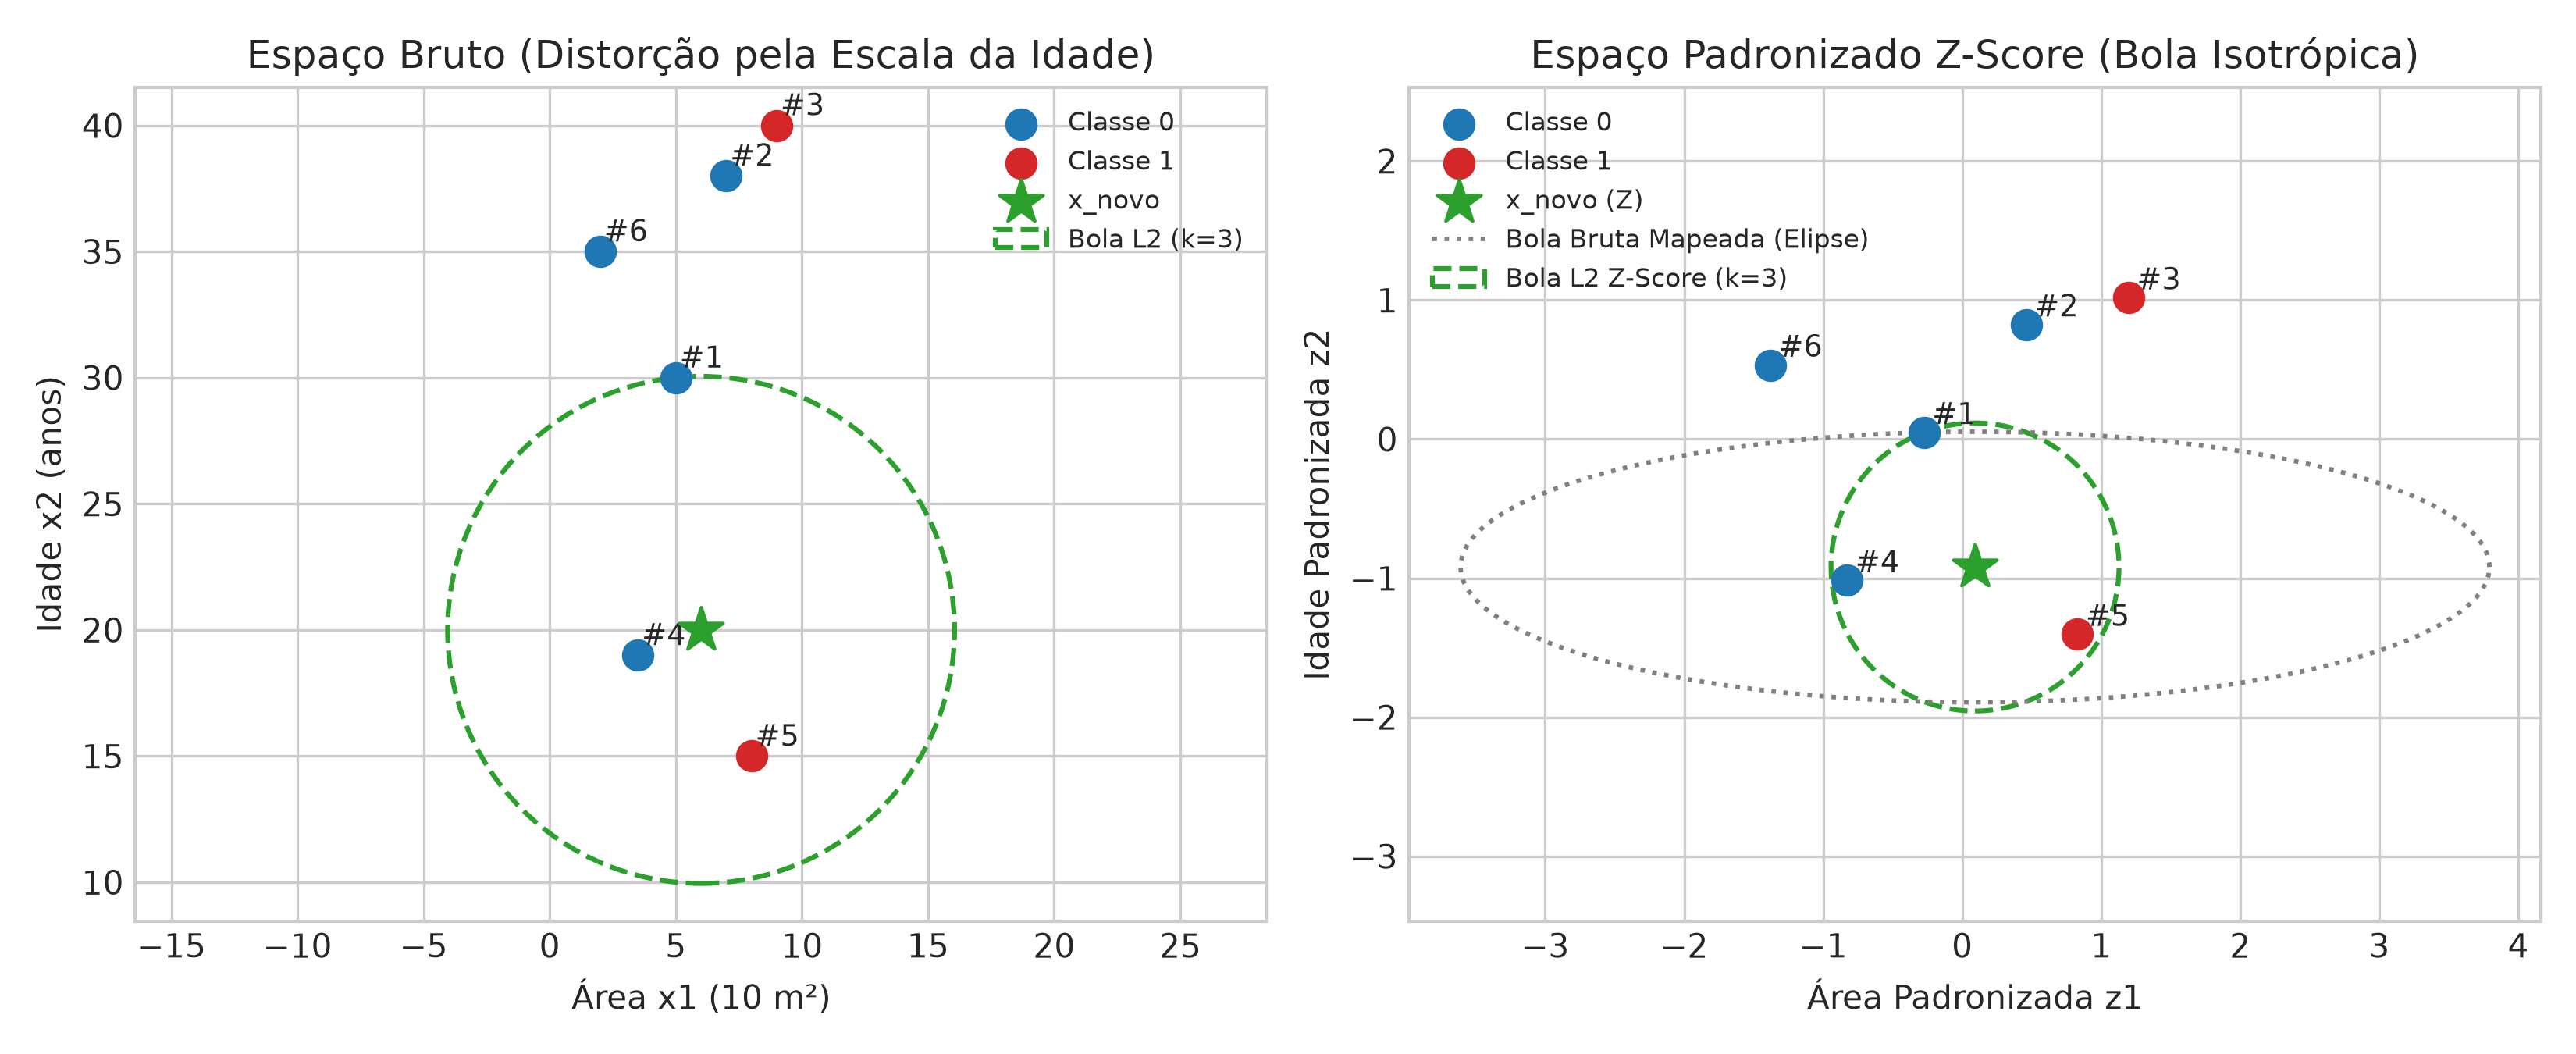

In [4]:
from src.questao1 import run_questao1
res_q1 = run_questao1(save_figures=True)
display(Image('figures/q1_bolas_metricas_escala.png'))

---
## Questão 2: Regressão Linear, Posto e Mínimos Quadrados Clássicos (OLS)

**Objetivo:** Formular a matriz de projeto com termo independente $\mathbf{X} = [\mathbf{1}, \mathbf{x}_1, \mathbf{x}_2] \in \mathbb{R}^{6 \times 3}$, calcular a matriz de Gram $\mathbf{X}^T \mathbf{X}$, resolver as equações normais $(\mathbf{X}^T \mathbf{X})\hat{\mathbf{w}} = \mathbf{X}^T \mathbf{y}$ e verificar a ortogonalidade fundamental dos resíduos: $\mathbf{X}^T \mathbf{e} = \mathbf{0}$.

=== QUESTÃO 2: REGRESSÃO LINEAR, POSTO E OLS ===
Posto rk(X) = 3 | Posto rk([X|y]) = 4 -> Sistema Incompatível (Rouché-Capelli)
Com x3 = 2.5*x1: rk(X_tilde) = 3, rk(X_tilde^T X_tilde) = 3 (< 4, singular)
Matriz de Gram X^T X:
[[   6.     34.5   177.  ]
 [  34.5   235.25 1032.5 ]
 [ 177.   1032.5  5755.  ]]
Vetor X^T y: [ 18.1  121.95 533.  ]
Pesos ótimos w_hat = [ 0.646968  0.490887 -0.015353]
Norma máxima de ortogonalidade ||X^T (y - X w_hat)||_inf = 4.086e-14 (< 1e-10)
Predição linear para x_novo [6.0, 20.0]: y_lin = 3.285237 (vs k-NN k=3: 2.966667)



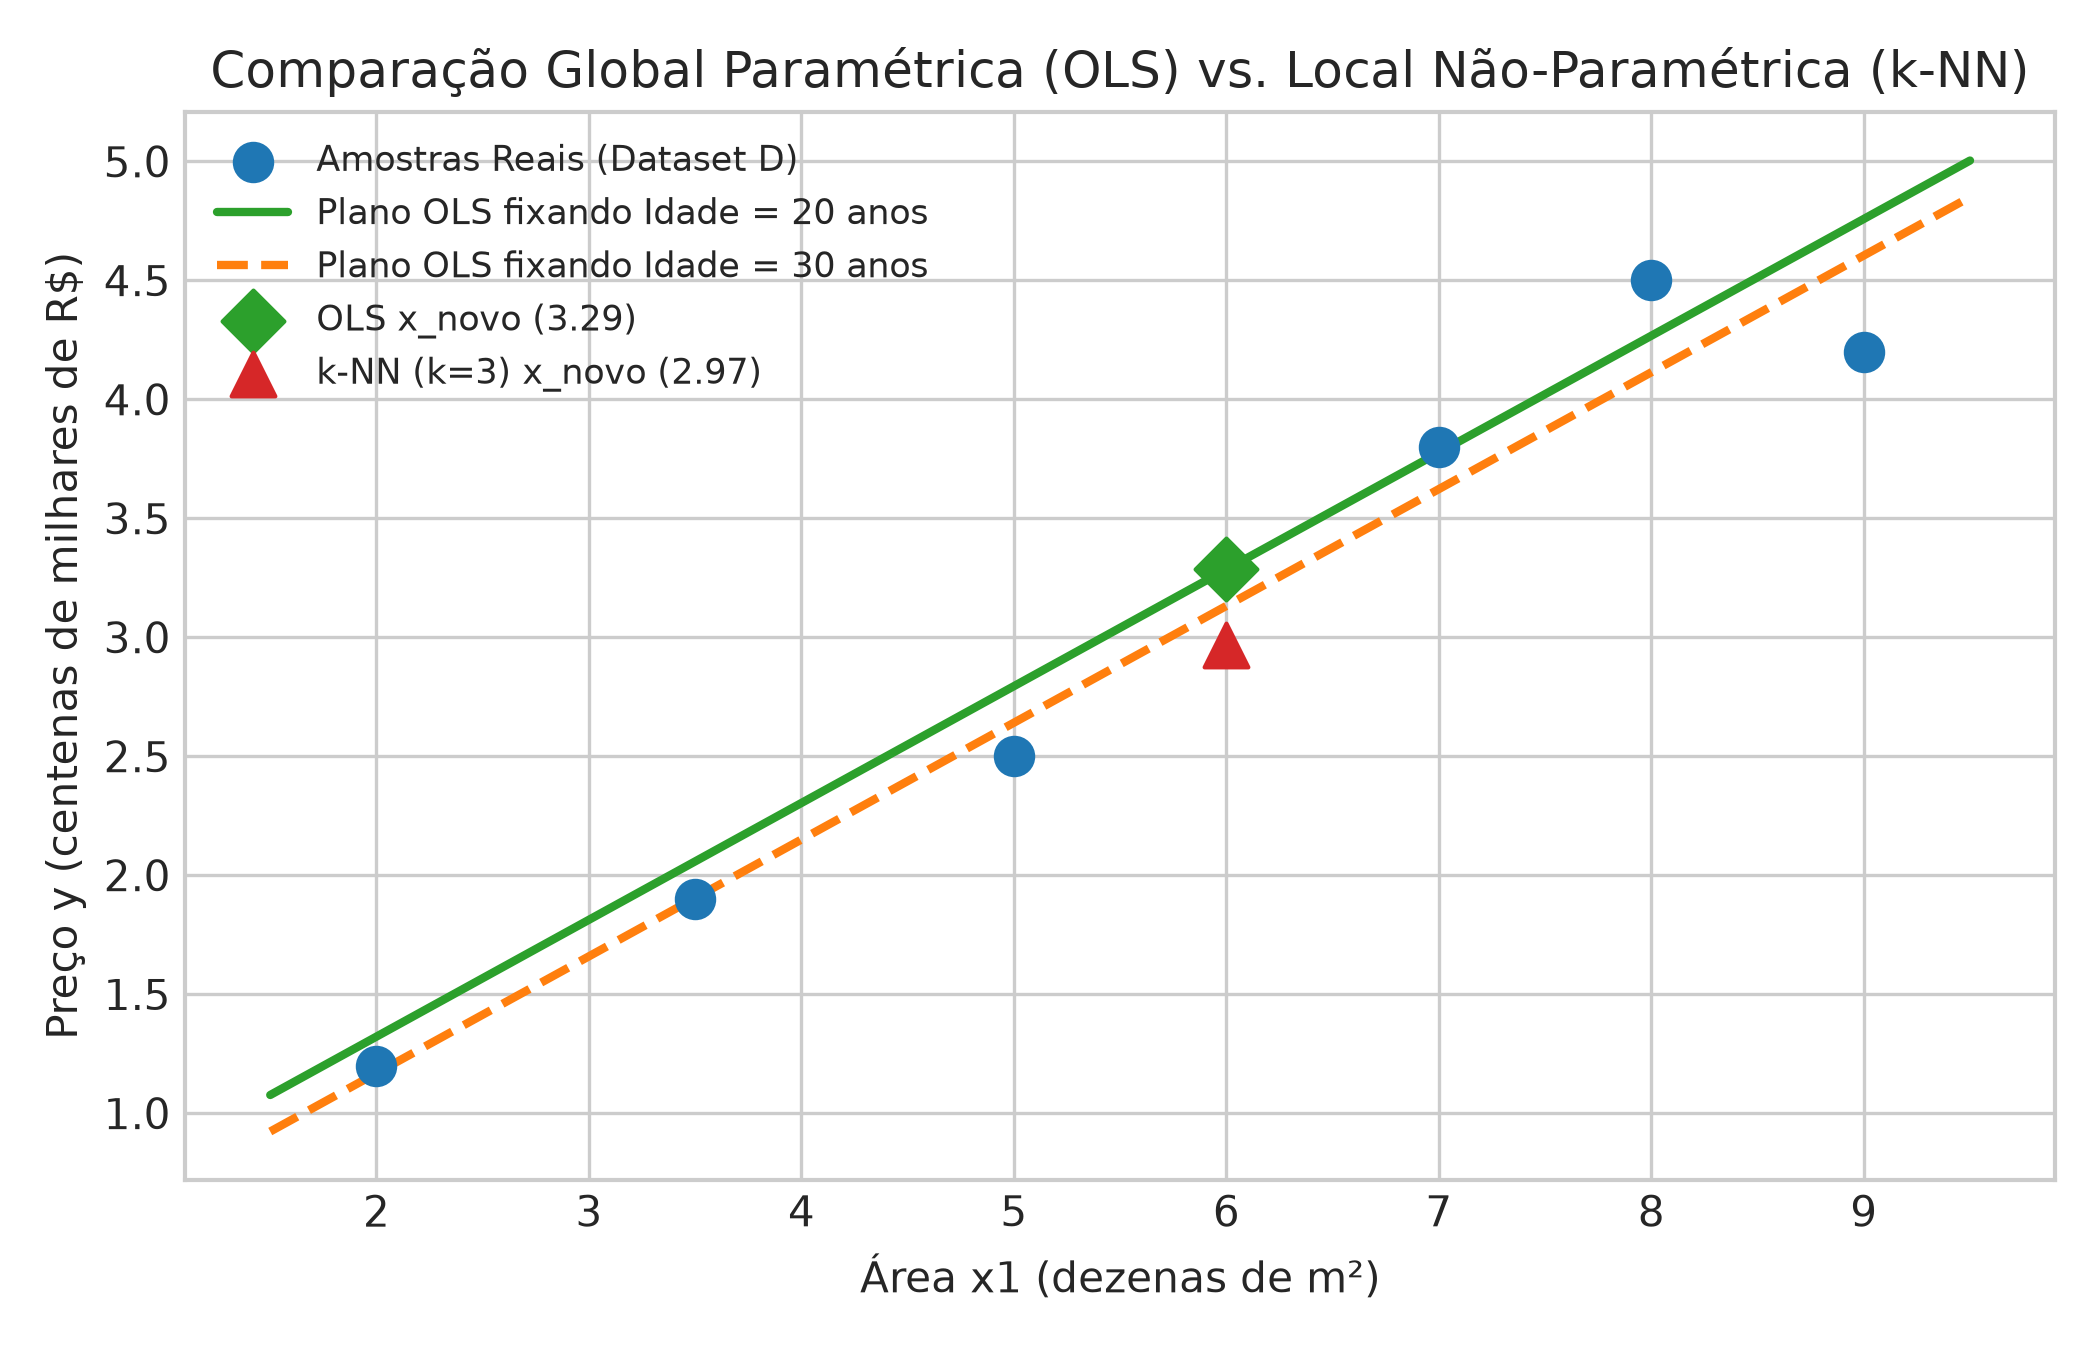

In [5]:
from src.questao2 import run_questao2
res_q2 = run_questao2(save_figures=True)
display(Image('figures/q2_ols_vs_knn_superficie.png'))

---
## Questão 3: Projeção Ortogonal, Teorema Espectral e SVD Compacta

**Objetivo:** Construir a matriz de projeção ortogonal $\mathbf{P} = \mathcal{A}(\mathcal{A}^T \mathcal{A})^{-1} \mathcal{A}^T$, testar suas propriedades (simetria $\mathbf{P} = \mathbf{P}^T$ e idempotência $\mathbf{P}^2 = \mathbf{P}$), deduzir analiticamente e verificar numericamente a SVD compacta $\mathcal{A} = \mathbf{U} \boldsymbol{\Sigma} \mathbf{V}^T$ e calcular a pseudoinversa de Moore-Penrose $\mathcal{A}^+$.

=== QUESTÃO 3: PROJEÇÃO ORTOGONAL, TEOREMA ESPECTRAL E SVD ===
w_hat = [1.666667 1.666667] | y_hat = [3.333333 1.666667 1.666667] | e_hat = [ 0.666667 -0.666667 -0.666667]
||A^T e_hat||_inf = 4.441e-16 (< 1e-14)
Autovalores de S = A^T A: [3. 1.] | Valores Singulares de A: [1.732051 1.      ]
kappa(S) = 3.0000 == [kappa(A)]^2 = 3.0000
Aproximação de Posto 1 A^(1):
[[1.  1. ]
 [0.5 0.5]
 [0.5 0.5]]
Erro espectral ||A - A^(1)||_2 = 1.0000000000 == sigma_2 = 1.0000000000
Decomposição Polar O = U V^T:
[[ 0.57735   0.57735 ]
 [-0.211325  0.788675]
 [ 0.788675 -0.211325]]
P = V Sigma V^T:
[[1.366025 0.366025]
 [0.366025 1.366025]]



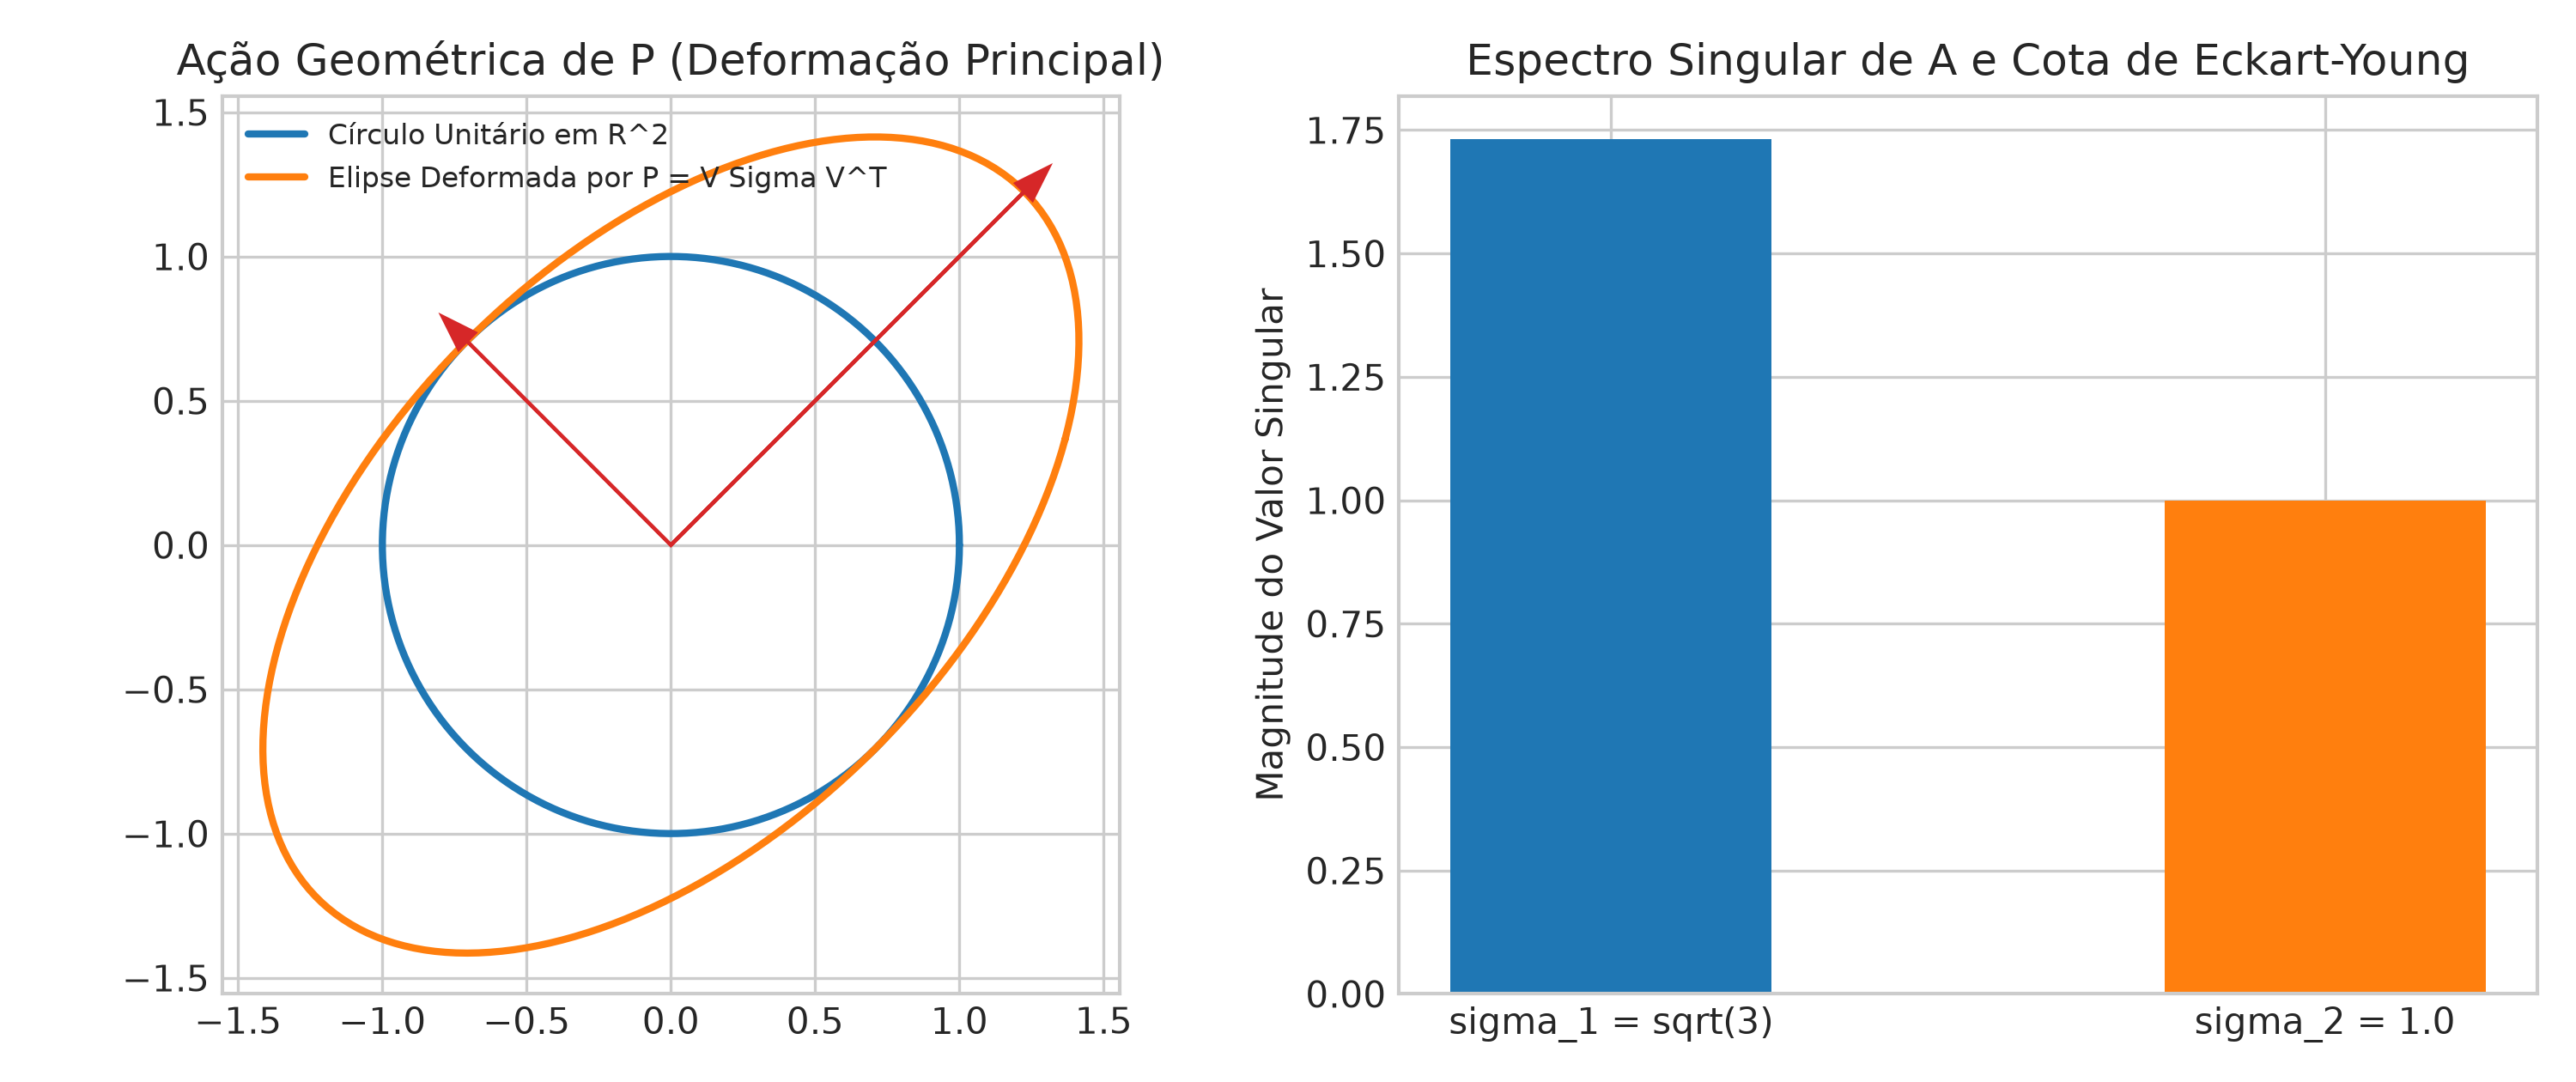

In [6]:
from src.questao3 import run_questao3
res_q3 = run_questao3(save_figures=True)
display(Image('figures/q3_svd_projecao_polar.png'))

---
## Questão 4: Cálculo Diferenciável, Hessiana e Vales Planos (Ridge Regression)

**Objetivo:** Analisar a função de custo $f(\mathbf{w}) = \frac{1}{2} \|\mathcal{B}\mathbf{w} - \mathbf{y}_{\mathcal{B}}\|_2^2$ sobre a matriz $\mathcal{B}$ (com colinearidade linear $\mathbf{x}_3 = \mathbf{x}_1 + \mathbf{x}_2$).

Provar que $\det(\mathcal{B}^T \mathcal{B}) = 0$, identificar o autovalor nulo $\lambda_3 = 0$, explicitar o vale plano e demonstrar como a regularização de Ridge $(\mathcal{B}^T \mathcal{B} + \lambda \mathbf{I})$ restaura a estrita convexidade da Hessiana.

=== QUESTÃO 4: CÁLCULO DIFERENCIÁVEL, HESSIANA E VALES PLANOS (RIDGE) ===
Em beta_0=[1,1,1]^T: L(beta_0) = 6.0000 | grad_analitico = [ 6. 10. 16.] | u* = [-0.303046 -0.505076 -0.808122]
Diferença máxima ||grad_analitico - grad_FD(h=1e-5)||_inf = 1.048e-10
Autovalores Hessiana 2 B^T B: [-0.  6. 42.]
Autovalores Hessiana Ridge 2(B^T B + I): [ 2.  8. 44.]
Solução OLS norma mínima beta* = [0.809524 0.142857 0.952381] | L(beta*) = 0.761905
Solução Ridge (lambda=1) beta_ridge = [0.704545 0.204545 0.909091] | L_1(beta_ridge) = 2.227273
Invariância no vale plano confirmada: max|L(beta* + t*n) - L(beta*)| = 0.0
Tabela ao longo do núcleo n=[1,1,-1]^T (t in [-2, 2]):
  t = -2.00 | L(beta*+tn) = 0.761905 | L_1(beta_1+tn) = 14.227273 (diff = 12.000000)
  t = -1.00 | L(beta*+tn) = 0.761905 | L_1(beta_1+tn) = 5.227273 (diff = 3.000000)
  t = +0.00 | L(beta*+tn) = 0.761905 | L_1(beta_1+tn) = 2.227273 (diff = 0.000000)
  t = +1.00 | L(beta*+tn) = 0.761905 | L_1(beta_1+tn) = 5.227273 (diff = 3.000000)
 

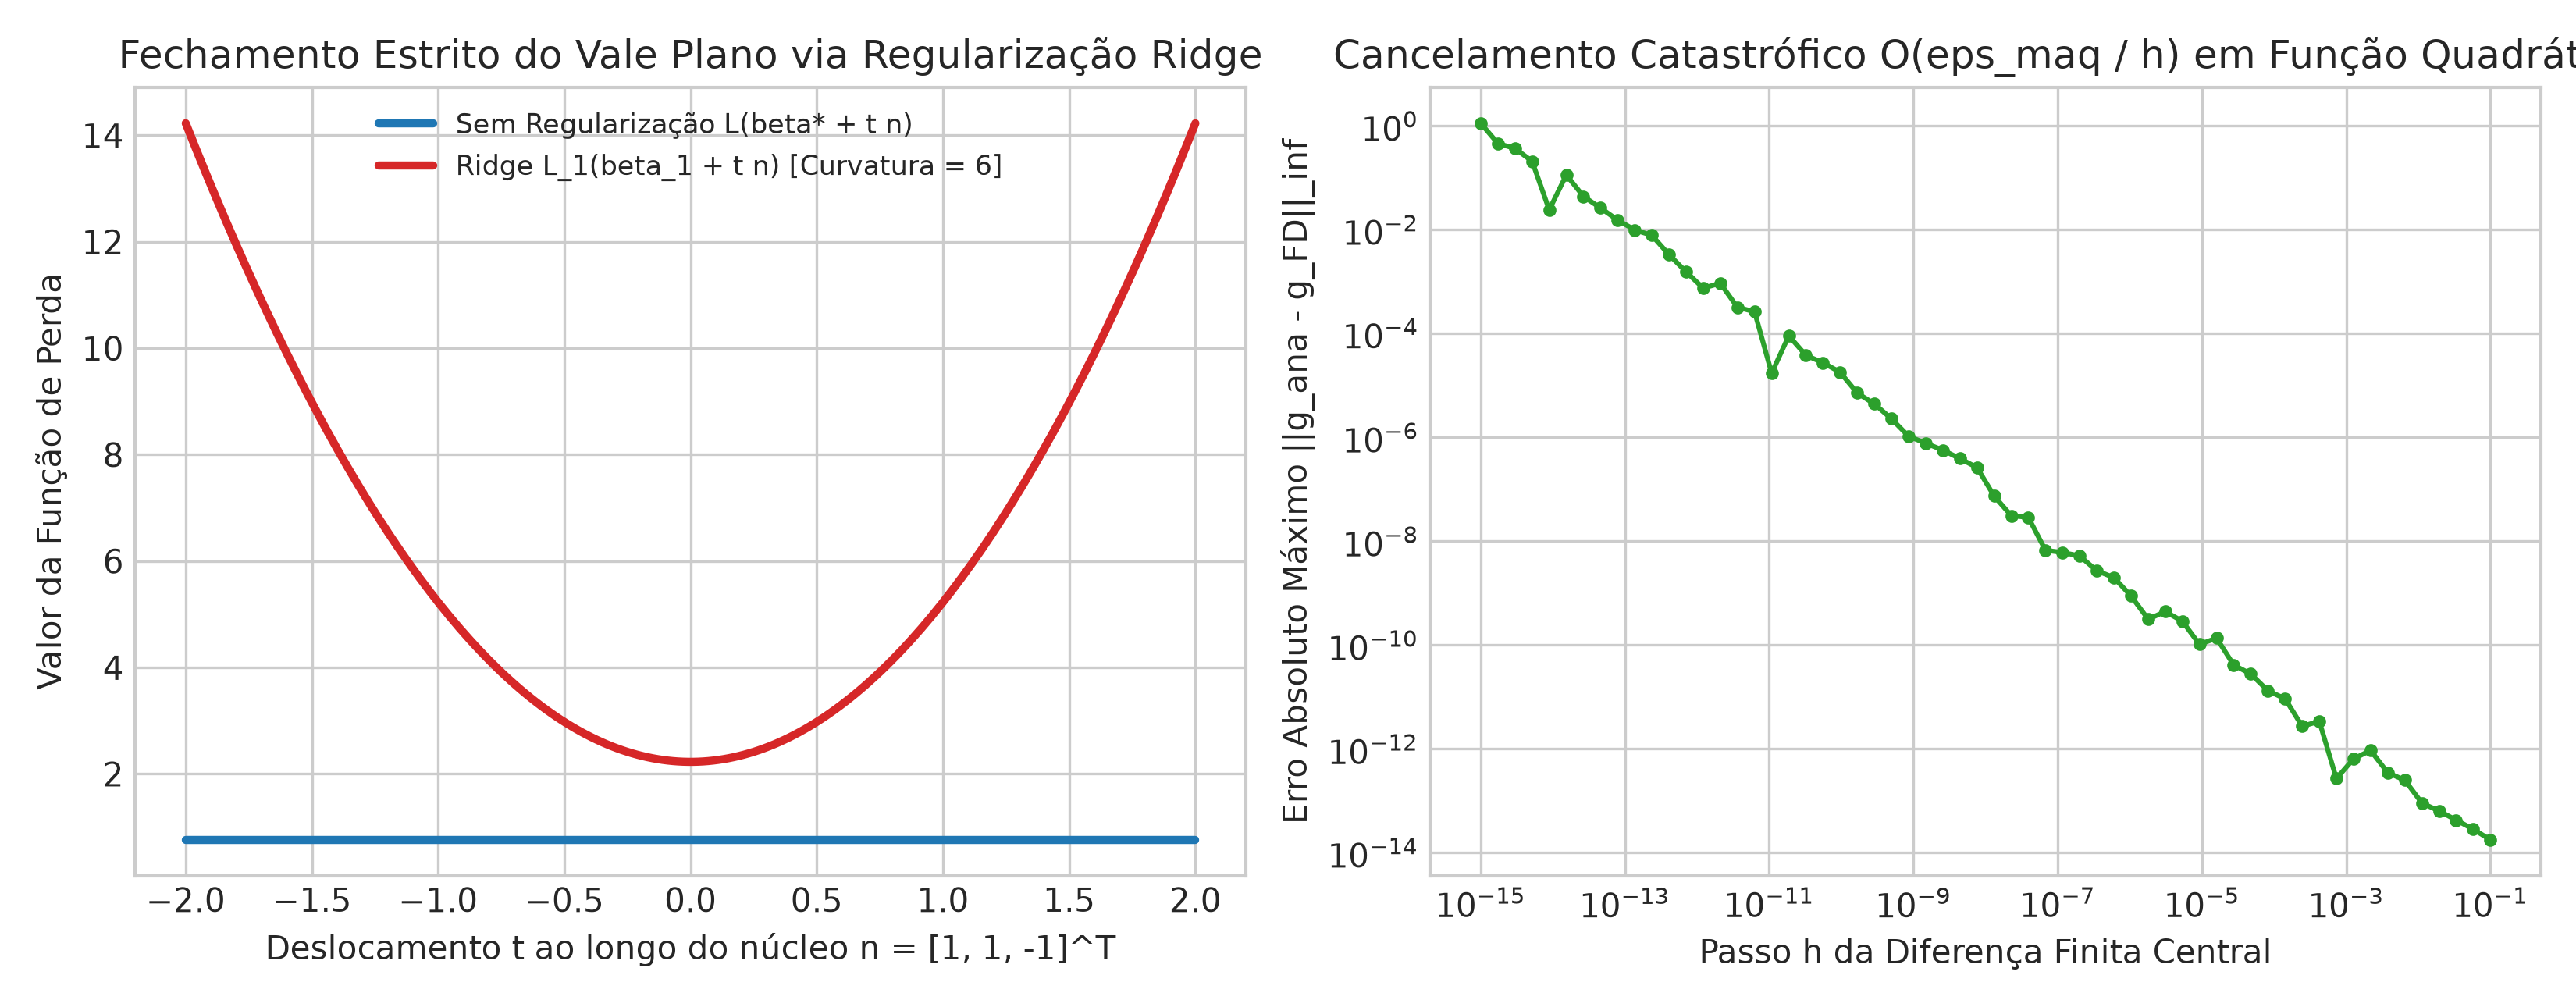

In [7]:
from src.questao4 import run_questao4
res_q4 = run_questao4(save_figures=True)
display(Image('figures/q4_vale_plano_vs_ridge.png'))

---
## Questão 5: Análise de Convergência da Descida do Gradiente e Regressão Logística

**Objetivo:**
1. Calcular o número de condição $\kappa = \lambda_{\max}/\lambda_{\min}$ e a taxa ótima $\alpha^* = \frac{2}{\lambda_{\max} + \lambda_{\min}}$;
2. Implementar a Regressão Logística Binária (perda de entropia cruzada) no Dataset $\mathcal{D}$ com os rótulos de perfil $c_i \in \{0, 1\}$;
3. Comparar a convergência da Descida do Gradiente de 1ª ordem contra o **Método de Newton de 2ª ordem** (Newton-Raphson).

=== QUESTÃO 5: CONDICIONAMENTO E REGRESSÃO LOGÍSTICA REGULARIZADA ===
Número de condição bruto kappa(2 X^T X) = 14714.2235
Número de condição Z-score kappa(2 X_tilde^T X_tilde): ddof=1 -> 1.3410 | ddof=0 -> 1.2350
OLS GD (2000 iterações): Perda Bruta = 29.493202 vs Perda Padronizada = 0.239147 (Ótimo = 0.239147)
Reg. Logística GD (2000 it, lambda=0.1): Perda Bruta = 0.335453 vs Padronizada = 0.507517
Regressão Logística (lambda=0.1, padronizado ddof=1): w_hat = [-0.407885  0.896095 -0.221284] (||w_GD - w_Newton||_2 = 1.39e-15)
Probabilidades estimadas: [0.3394 0.4557 0.6082 0.2839 0.6559 0.1464] | Classes previstas: [0 0 1 0 1 0] | Acurácia = 100.0%



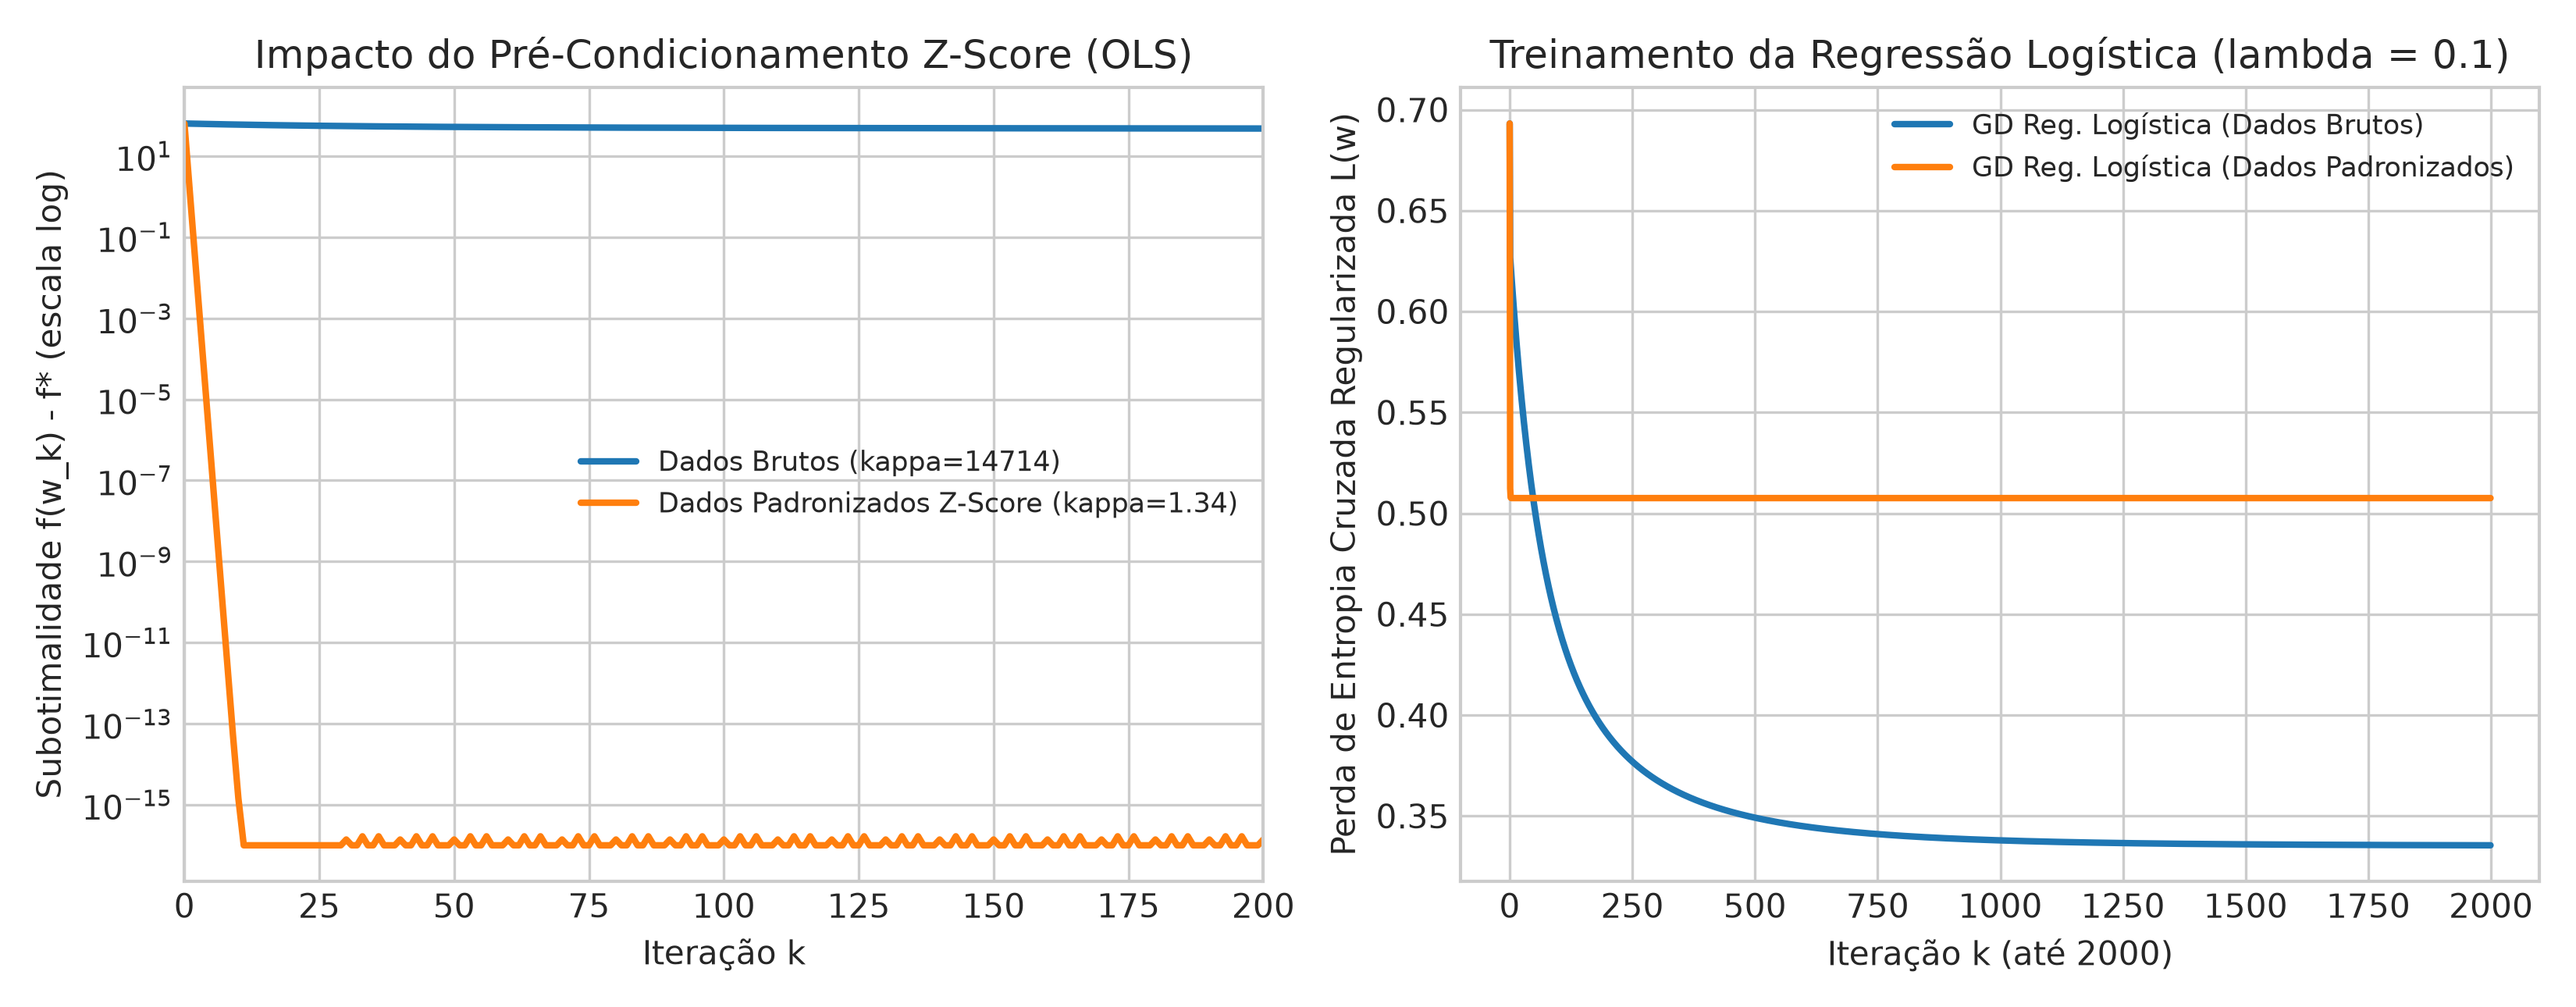

In [8]:
from src.questao5 import run_questao5
res_q5 = run_questao5(save_figures=True)
display(Image('figures/q5_condicionamento_gd_logistica.png'))

---
## Questão 6: Otimização Estocástica, Momento e Métodos Adaptativos

**Objetivo:** Implementar em NumPy puro os quatro algoritmos fundamentais de otimização de primeira ordem:
1. **GD Determinístico** (Full-Batch);
2. **SGD Estocástico** (com ruído amostral de mini-batch);
3. **GD com Momento de Polyak** (Heavy-Ball);
4. **Adam** (Adaptive Moment Estimation com estimativas de 1º e 2º momentos desviesadas).

Plotar a curva comparativa da perda ao longo das iterações.

=== QUESTÃO 6: OTIMIZAÇÃO ESTOCÁSTICA, MOMENTO, ADAM E NEWTON ===
Solução Analítica OLS (Padronizada): w_ols = [ 3.016667  1.333099 -0.158585]
  SGD Mini-Batch B=1: w_final = [ 3.001763  1.326368 -0.147281] | ||w - w_ols||_2 = 0.019880
  SGD Mini-Batch B=2: w_final = [ 3.001722  1.326004 -0.148425] | ||w - w_ols||_2 = 0.019414
  SGD Mini-Batch B=6: w_final = [ 3.002145  1.324886 -0.151195] | ||w - w_ols||_2 = 0.018247
Iterações até ||w_t||_2 < 1e-6 na quadrática f(w1,w2) = 0.5*(100*w1^2 + w2^2):
  GD_Chebyshev   : 824 iterações
  Polyak         : 302 iterações
  NAG            : 209 iterações
  Adam           : 353 iterações
  Newton         : 1 iterações



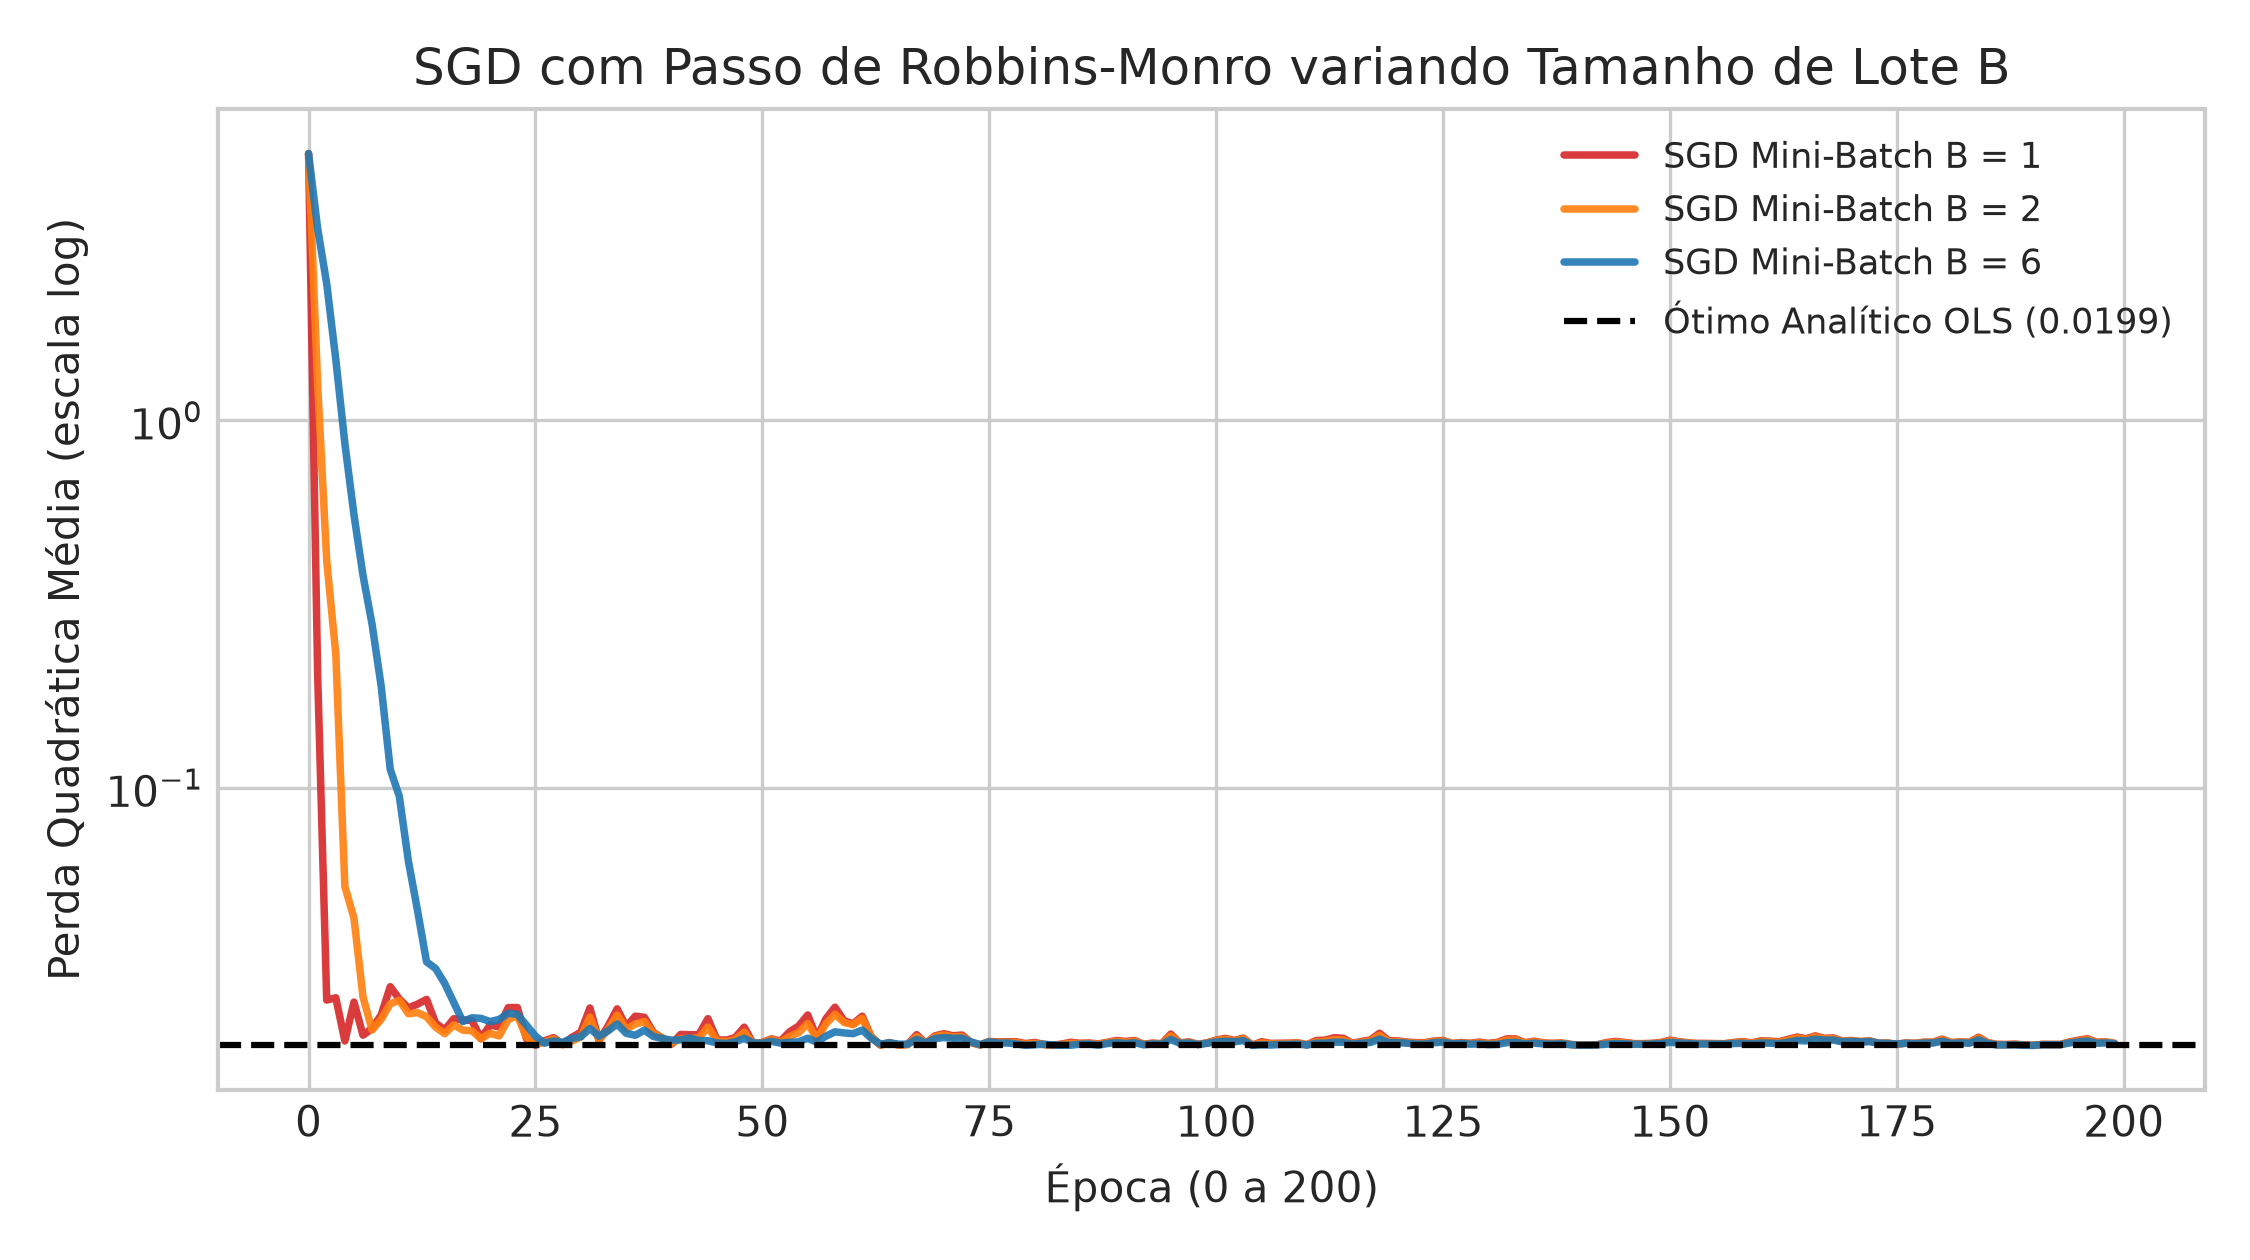

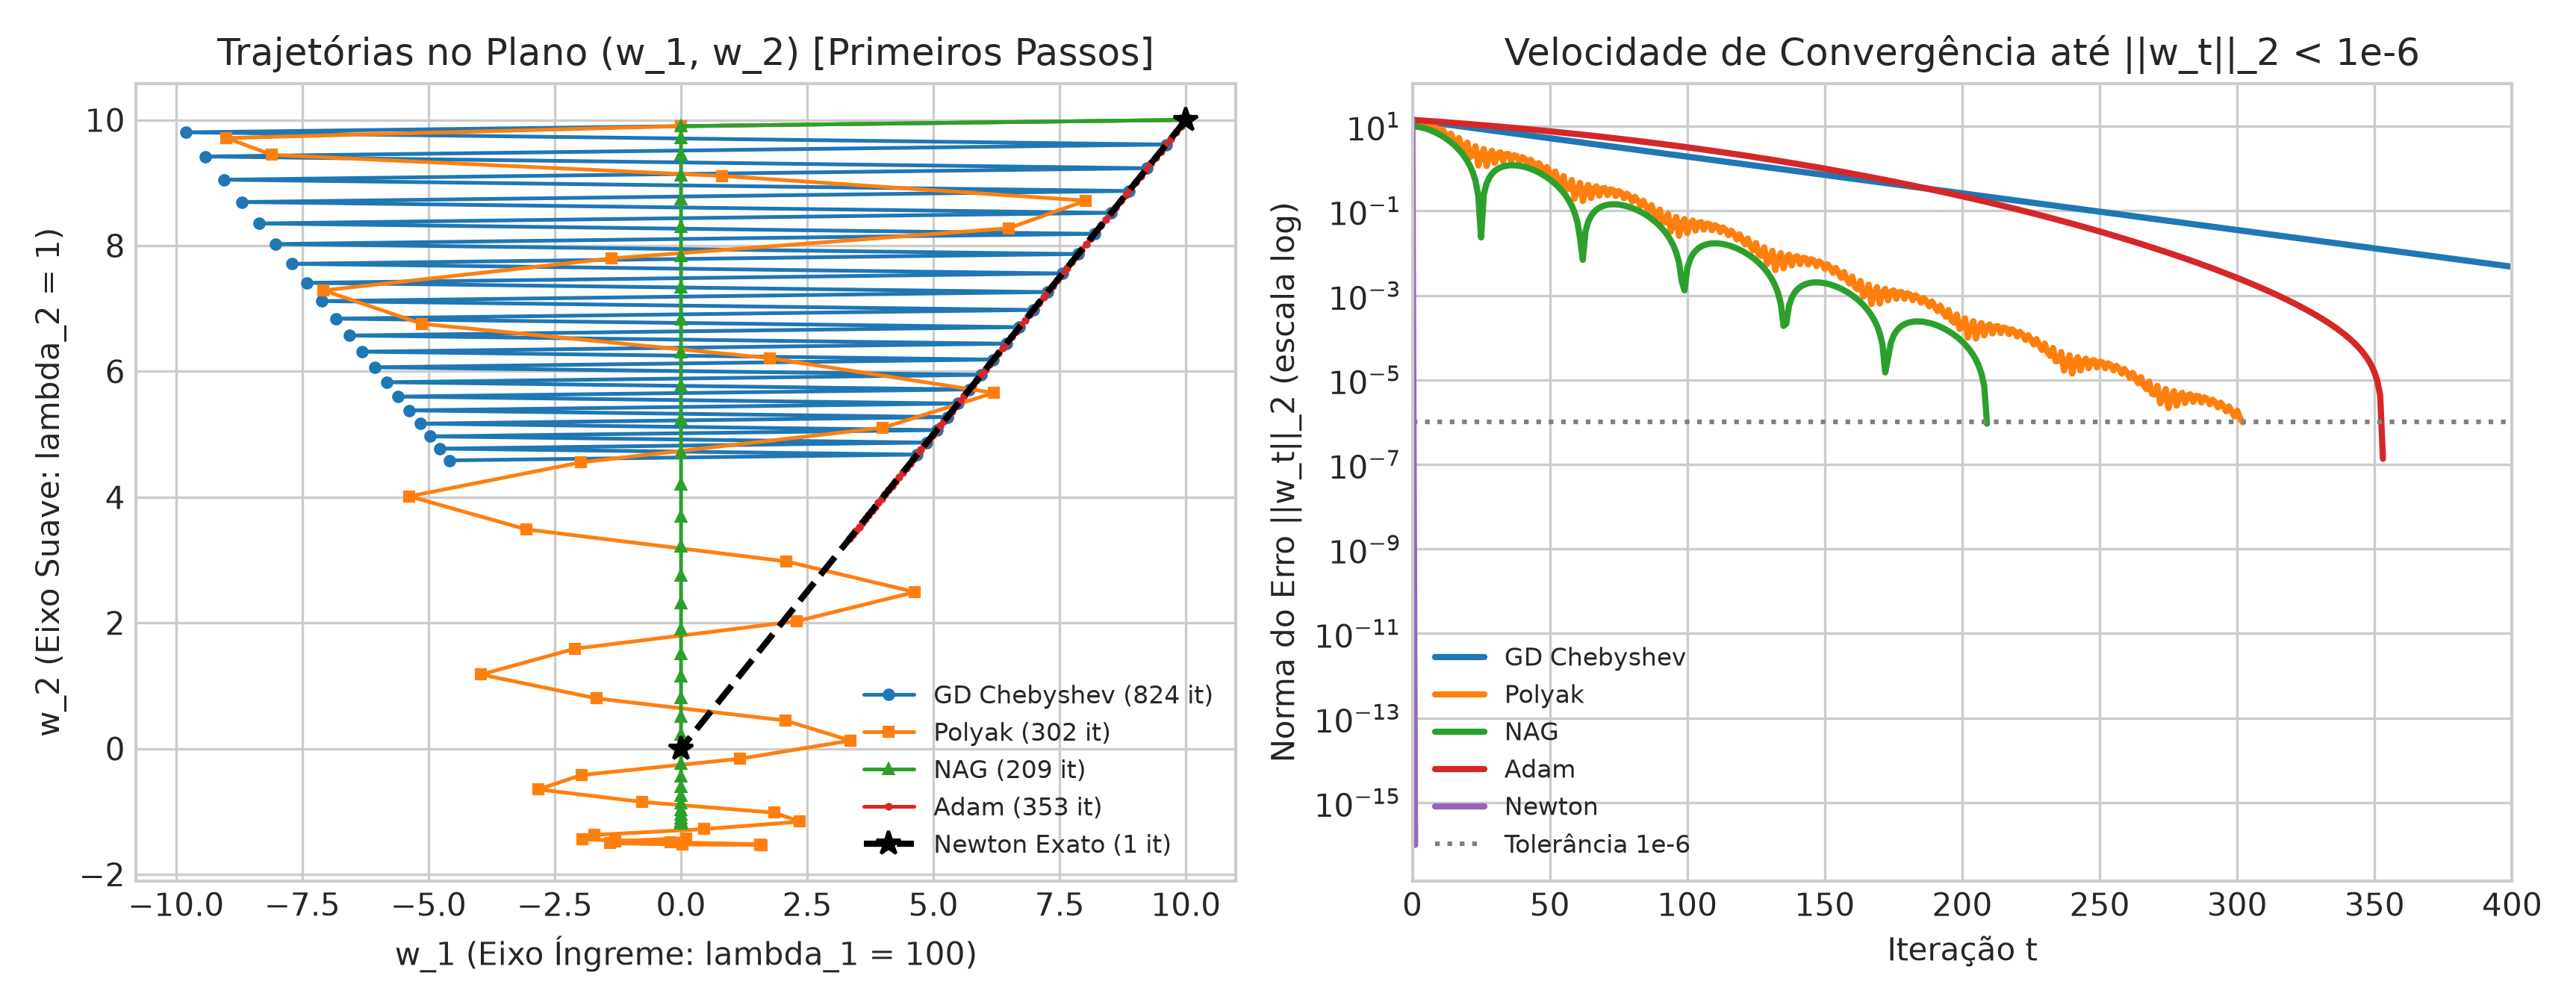

In [9]:
from src.questao6 import run_questao6
res_q6 = run_questao6(save_figures=True)
display(Image('figures/q6_minibatch_sgd_robbins_monro.png'))
display(Image('figures/q6_quadratica_trajetorias_otimizadores.png'))

---
## Questão Bônus: Otimização Não-Suave, Operadores Proximais e o Algoritmo ISTA (Lasso)

**Objetivo:** Demonstrar o operador de limiarização suave (*Soft-Thresholding*) e o algoritmo ISTA (*Iterative Shrinkage-Thresholding Algorithm*) para otimização da perda com regularização $L_1$:

$$\min_{\mathbf{w}} \frac{1}{2N} \|\mathbf{X}\mathbf{w} - \mathbf{y}\|_2^2 + \lambda \|\mathbf{w}\|_1$$

onde o operador proximal é dado analiticamente por:
$$\operatorname{prox}_{\alpha \lambda \|\cdot\|_1}(v)_j = \operatorname{sgn}(v_j) \max(|v_j| - \alpha \lambda, 0)$$

=== QUESTÃO BÔNUS: OTIMIZAÇÃO NÃO-SUAVE E ALGORITMO ISTA/FISTA ===
w_true   = [ 3.  -2.   1.5  0.   0.   0.   0.   0.   0.   0. ]
w_ista   = [ 2.8817 -1.8598  1.3912  0.     -0.      0.      0.     -0.     -0.
  0.    ]
w_fista  = [ 2.8817 -1.8598  1.3912  0.     -0.      0.      0.     -0.     -0.
  0.    ]
Suporte verdadeiro: [0, 1, 2] | Suporte recuperado pelo ISTA: [0, 1, 2]
Coeficientes nulos exatos (j >= 3): 7 de 7



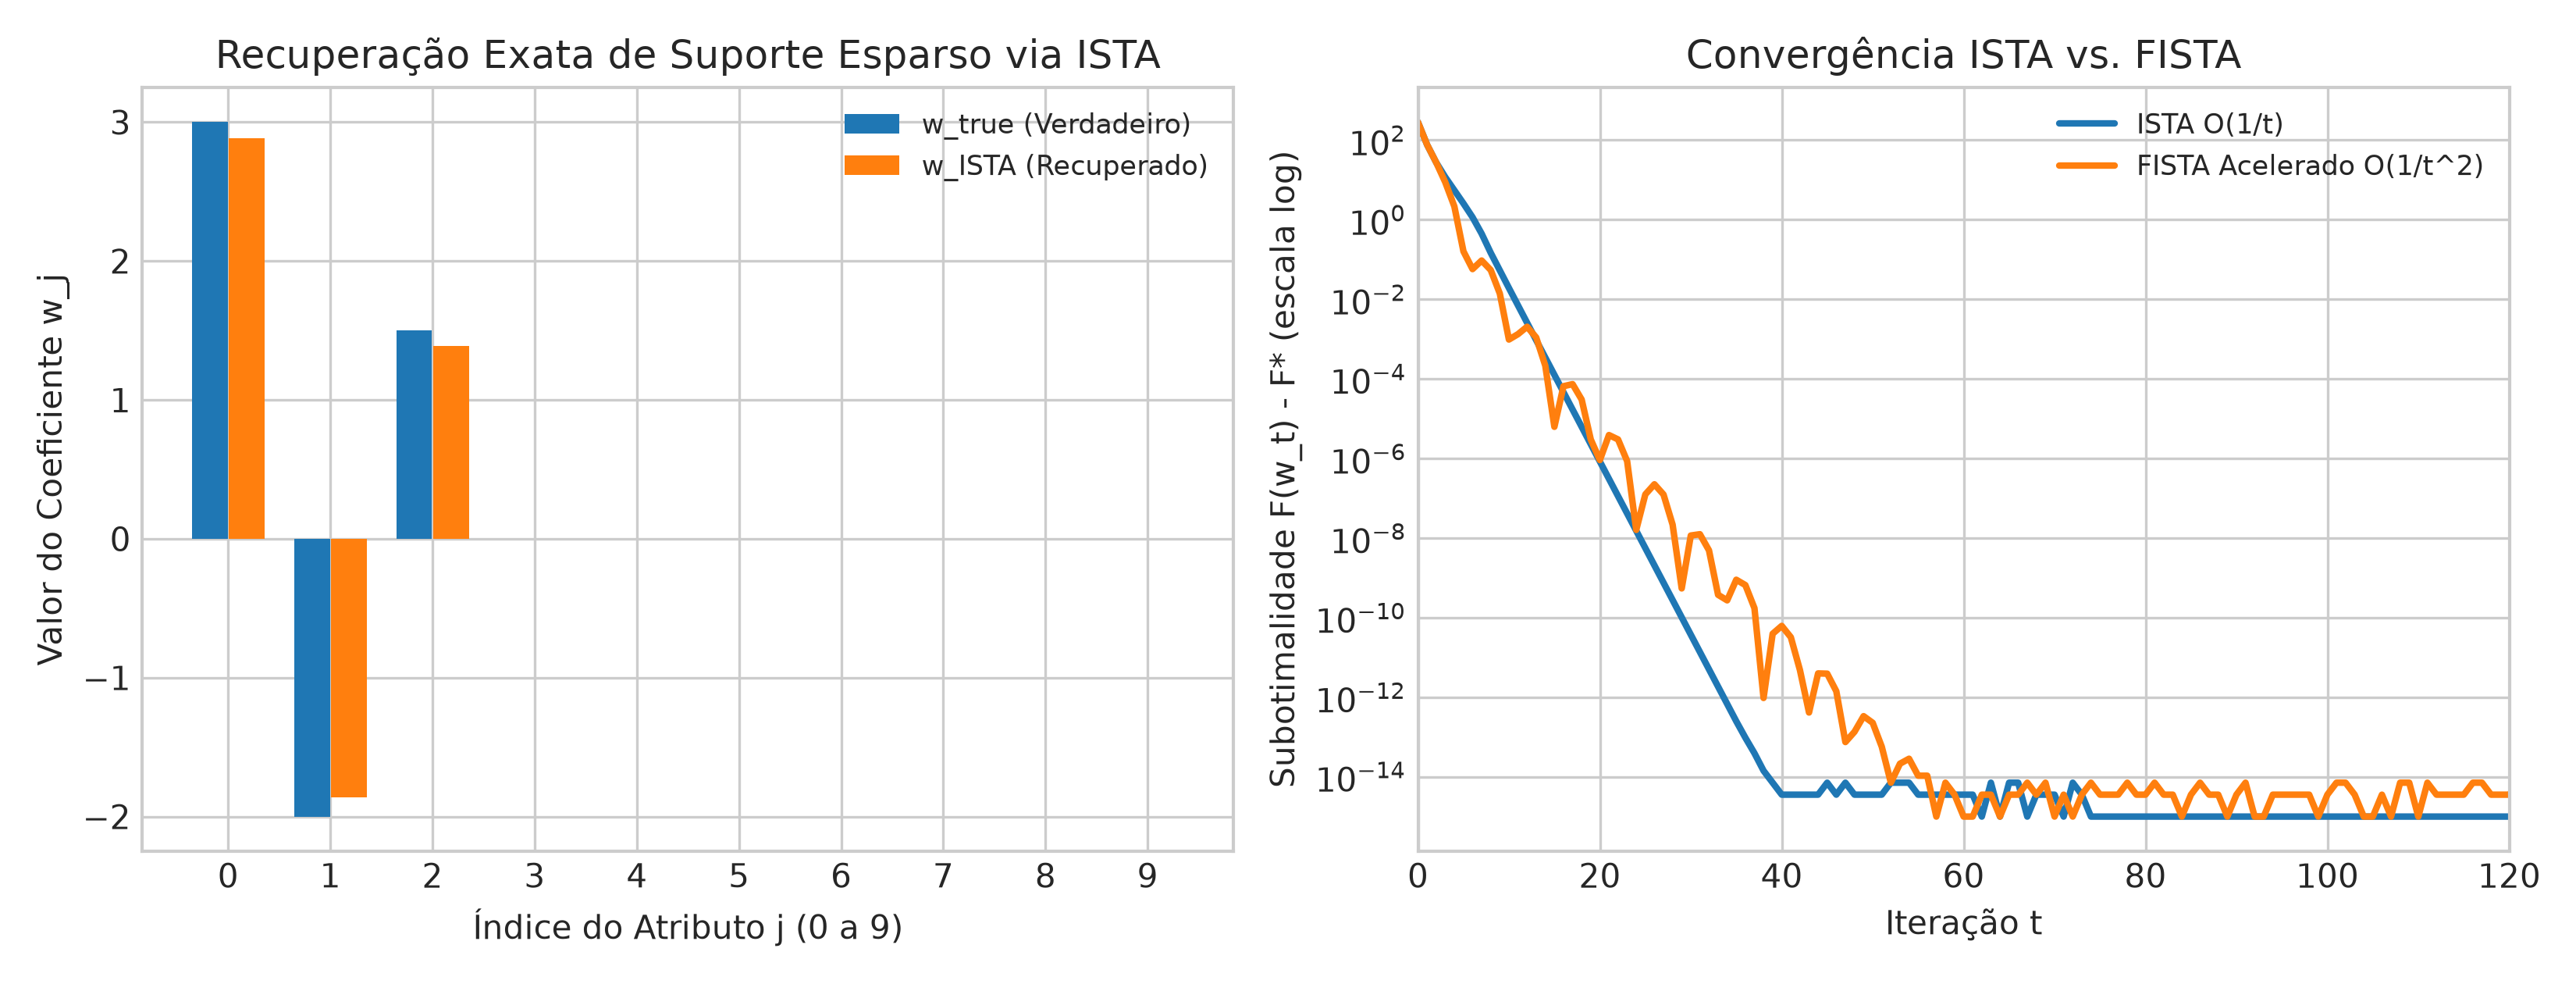

In [10]:
from src.questao_bonus import run_questao_bonus
res_bonus = run_questao_bonus(save_figures=True)
display(Image('figures/qbonus_ista_fista_esparsidade.png'))